In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

In [4]:
df = pd.read_csv("mandi_dataset.csv")

print("Shape:", df.shape)
display(df.head())
print(df.info())


Shape: (16770, 10)


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
0,Odisha,Mayurbhanja,Baripada APMC,Tomato,Tomato,Medium,12/11/2026,3000.0,4000.0,3500.0
1,Odisha,Mayurbhanja,Baripada APMC,Pointed gourd(Parval),Other,Medium,12/11/2026,3000.0,4000.0,3500.0
2,Tripura,Dhalai,Kulai APMC,Banana - Green,Banana - Green,Grade B,12/11/2026,2000.0,2500.0,2200.0
3,Tripura,Dhalai,Kulai APMC,Bottle gourd,Bottle Gourd,Grade B,12/11/2026,2500.0,3000.0,2800.0
4,Tripura,Dhalai,Kulai APMC,Cucumbar(Kheera),Cucumbar,Grade B,12/11/2026,5600.0,6000.0,5800.0


<class 'pandas.DataFrame'>
RangeIndex: 16770 entries, 0 to 16769
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   State              16770 non-null  str    
 1   District           16770 non-null  str    
 2   Market             16770 non-null  str    
 3   Commodity          16770 non-null  str    
 4   Variety            16770 non-null  str    
 5   Grade              16770 non-null  str    
 6   Arrival_Date       16770 non-null  str    
 7   Min_x0020_Price    16770 non-null  float64
 8   Max_x0020_Price    16770 non-null  float64
 9   Modal_x0020_Price  16770 non-null  float64
dtypes: float64(3), str(7)
memory usage: 1.3 MB
None


In [5]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
print(df.dtypes)
print("\\nSummary statistics:")
display(df.describe(include="all").T)
print("\\nUnique values:")
display(df.nunique())


Rows and columns: (16770, 10)
\nColumn names:
['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_x0020_Price', 'Max_x0020_Price', 'Modal_x0020_Price']
\nData types:
State                    str
District                 str
Market                   str
Commodity                str
Variety                  str
Grade                    str
Arrival_Date             str
Min_x0020_Price      float64
Max_x0020_Price      float64
Modal_x0020_Price    float64
dtype: object
\nSummary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,16770,29,Tamil Nadu,6998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,16770,497,Salem,601,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Market,16770,1759,Anna nagar(Uzhavar Sandhai ),70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Commodity,16770,252,Tomato,575,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Variety,16770,496,Other,3464,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Grade,16770,12,Local,9532,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Arrival_Date,16770,1,12/11/2026,16770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Min_x0020_Price,16770.0,NaN,NaN,NaN,4936.705833,5451.932867,0.01,2461.0,3800.0,6000.0,180000.0
Max_x0020_Price,16770.0,NaN,NaN,NaN,5822.67199,6467.282701,0.01,2865.0,4430.0,7000.0,200000.0
Modal_x0020_Price,16770.0,NaN,NaN,NaN,5406.263487,5885.613291,0.01,2655.0,4000.0,6500.0,190000.0


\nUnique values:


State                  29
District              497
Market               1759
Commodity             252
Variety               496
Grade                  12
Arrival_Date            1
Min_x0020_Price      1384
Max_x0020_Price      1649
Modal_x0020_Price    1611
dtype: int64

In [6]:
df.columns = (df.columns.str.strip()
              .str.replace(r'[^A-Za-z0-9]+', '_', regex=True)
              .str.strip('_'))

df = df.rename(columns={
    'Min_x0020_Price': 'Min_Price',
    'Max_x0020_Price': 'Max_Price',
    'Modal_x0020_Price': 'Modal_Price'
})

df['Arrival_Date'] = pd.to_datetime(df['Arrival_Date'], dayfirst=True, errors='coerce')


print("Missing values:\\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

price_cols = ['Min_Price', 'Max_Price', 'Modal_Price']
for col in price_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    
df = df.dropna(subset=price_cols + ['State', 'District', 'Market', 'Commodity'])
df = df[(df[price_cols] > 0).all(axis=1)]
print("Cleaned shape:", df.shape)


Missing values:\n State           0
District        0
Market          0
Commodity       0
Variety         0
Grade           0
Arrival_Date    0
Min_Price       0
Max_Price       0
Modal_Price     0
dtype: int64
Duplicate rows: 0
Cleaned shape: (16770, 10)


Commodity
Tomato                   575
Brinjal                  551
Onion                    529
Potato                   486
Green Chilli             443
Paddy(Common)            441
Banana                   436
Bhindi(Ladies Finger)    420
Cauliflower              413
Cabbage                  396
Name: count, dtype: int64


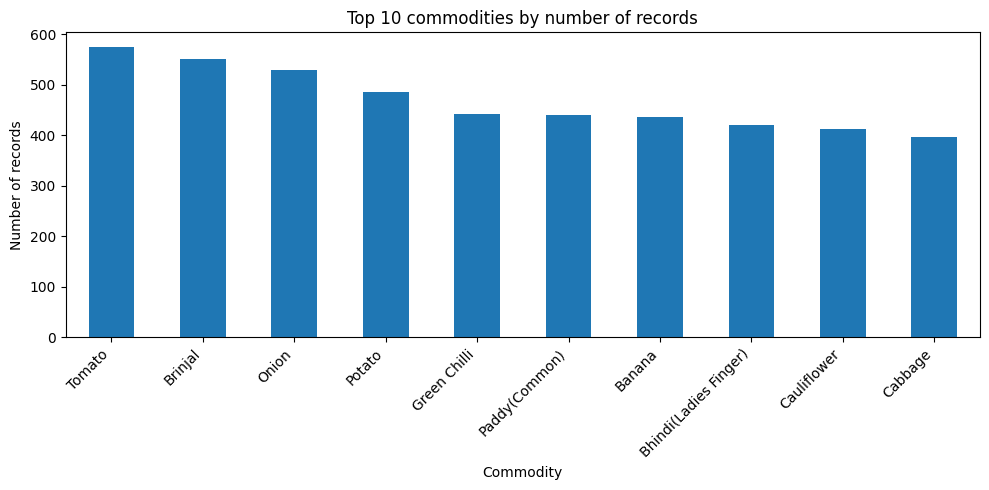

In [10]:
print(df['Commodity'].value_counts().head(10))
plt.figure(figsize=(10, 5))
df['Commodity'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 commodities by number of records')
plt.xlabel('Commodity')
plt.ylabel('Number of records')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()




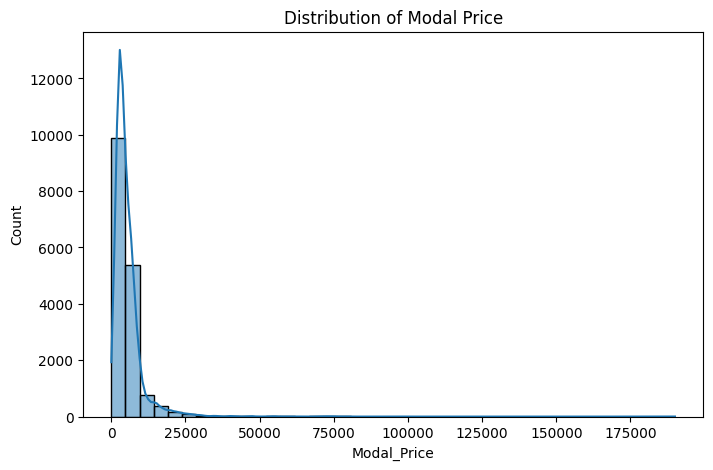

In [11]:


plt.figure(figsize=(8, 5))
sns.histplot(df['Modal_Price'], bins=40, kde=True)
plt.title('Distribution of Modal Price')
plt.show()




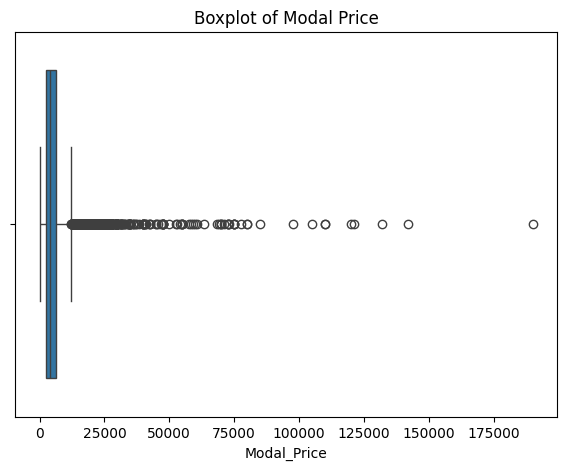

In [12]:


plt.figure(figsize=(7, 5))
sns.boxplot(x=df['Modal_Price'])
plt.title('Boxplot of Modal Price')
plt.show()


,Min_Price,Max_Price,Modal_Price
Min_Price,1.000000,0.936356,0.979884
Max_Price,0.936356,1.000000,0.977410
Modal_Price,0.979884,0.977410,1.000000


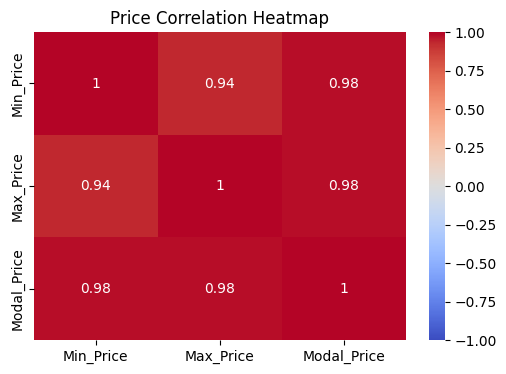

In [13]:
corr = df[['Min_Price', 'Max_Price', 'Modal_Price']].corr(method='pearson')
display(corr)
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Price Correlation Heatmap')
plt.show()


In [14]:
target = 'Modal_Price'
numeric_features = ['Min_Price', 'Max_Price']
categorical_features = ['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade']

X = df[numeric_features + categorical_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_preprocess = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_preprocess = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_preprocess, numeric_features),
    ('cat', categorical_preprocess, categorical_features)
])

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 13416
Testing rows: 3354


In [17]:
simple_model = LinearRegression()
simple_model.fit(X_train[['Min_Price']], y_train)
simple_pred = simple_model.predict(X_test[['Min_Price']])

print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("MAE:", mean_absolute_error(y_test, simple_pred))
print("MSE:", mean_squared_error(y_test, simple_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, simple_pred)))
print("R2:", r2_score(y_test, simple_pred))

Intercept: 188.0477803515314
Coefficient: 1.0559276052894413
MAE: 467.6585843640861
MSE: 2384735.1282785977
RMSE: 1544.2587633808648
R2: 0.922386898574943


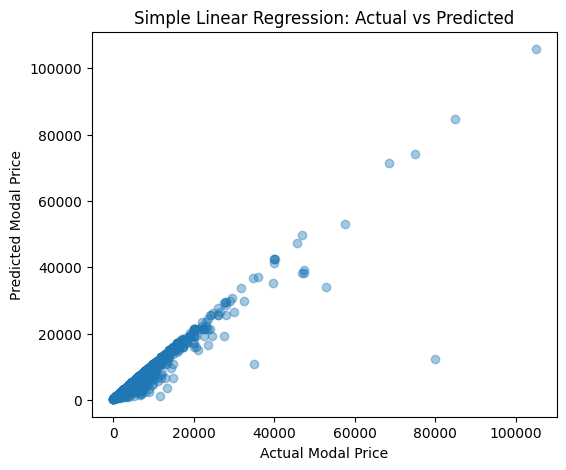

In [18]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, simple_pred, alpha=0.4)
plt.xlabel("Actual Modal Price")
plt.ylabel("Predicted Modal Price")
plt.title("Simple Linear Regression: Actual vs Predicted")
plt.show()

In [19]:
multiple_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', LinearRegression())
])
multiple_model.fit(X_train, y_train)
multiple_pred = multiple_model.predict(X_test)

def regression_results(name, actual, predicted):
    return {
        'Model': name,
        'MAE': mean_absolute_error(actual, predicted),
        'MSE': mean_squared_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R2': r2_score(actual, predicted)
    }

regression_table = [regression_results('Simple Linear', y_test, simple_pred),
                    regression_results('Multiple Linear', y_test, multiple_pred)]
pd.DataFrame(regression_table)


,Model,MAE,MSE,RMSE,R2
0,Simple Linear,467.658584,2.384735e+06,1544.258763,0.922387
1,Multiple Linear,213.623874,6.897111e+05,830.488478,0.977553


In [20]:
poly_numeric = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler())
])
poly_preprocessor = ColumnTransformer([
    ('num', poly_numeric, numeric_features),
    ('cat', categorical_preprocess, categorical_features)
])
polynomial_model = Pipeline([
    ('preprocess', poly_preprocessor),
    ('model', LinearRegression())
])
polynomial_model.fit(X_train, y_train)
polynomial_pred = polynomial_model.predict(X_test)

regression_table.append(regression_results('Polynomial degree 2', y_test, polynomial_pred))
display(pd.DataFrame(regression_table))


,Model,MAE,MSE,RMSE,R2
0,Simple Linear,467.658584,2.384735e+06,1544.258763,0.922387
1,Multiple Linear,213.623874,6.897111e+05,830.488478,0.977553
2,Polynomial degree 2,181.612785,3.216475e+06,1793.453322,0.895317


In [21]:
import statsmodels.api as sm

ols_X_train = sm.add_constant(X_train[['Min_Price', 'Max_Price']])
ols_model = sm.OLS(y_train, ols_X_train).fit()
print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:            Modal_Price   R-squared:                       0.990
Model:                            OLS   Adj. R-squared:                  0.990
Method:                 Least Squares   F-statistic:                 6.719e+05
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:50:05   Log-Likelihood:            -1.0471e+05
No. Observations:               13416   AIC:                         2.094e+05
Df Residuals:                   13413   BIC:                         2.094e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         42.9781      6.906      6.223      0.0

In [22]:
# Derive cut points from training data only to avoid test-set leakage
q1, q2 = y_train.quantile([1/3, 2/3]).values
def price_class(values):
    return pd.cut(values, bins=[-np.inf, q1, q2, np.inf],
                  labels=['Low', 'Medium', 'High'], include_lowest=True)

y_train_class = price_class(y_train)
y_test_class = price_class(y_test)

logistic_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))
])
logistic_model.fit(X_train, y_train_class)
logistic_pred = logistic_model.predict(X_test)
print(classification_report(y_test_class, logistic_pred, zero_division=0))


              precision    recall  f1-score   support

        High       0.98      0.97      0.98      1116
         Low       0.96      0.97      0.97      1124
      Medium       0.95      0.94      0.94      1114

    accuracy                           0.96      3354
   macro avg       0.96      0.96      0.96      3354
weighted avg       0.96      0.96      0.96      3354



In [24]:
# KNN: nearest-neighbor, distance-based lazy learning
knn_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

# Naive Bayes: probabilistic classifier; use dense one-hot output
dense_preprocessor = ColumnTransformer([
    ('num', numeric_preprocess, numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
], sparse_threshold=0)

nb_model = Pipeline([
    ('preprocess', dense_preprocessor),
    ('model', GaussianNB())
])

# Decision Tree: rule-based, divide-and-conquer model
tree_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', DecisionTreeClassifier(max_depth=12, random_state=42,
                                     class_weight='balanced'))
])

# SVM: finds separating boundaries between classes
svm_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', SVC(kernel='rbf', probability=True,
                  class_weight='balanced', random_state=42))
])

classification_models = {
    'Logistic Regression': logistic_model,
    'KNN': knn_model,
    'Naive Bayes': nb_model,
    'Decision Tree': tree_model,
    'SVM': svm_model
}

classification_results = []
for name, model in classification_models.items():
    model.fit(X_train, y_train_class)
    pred = model.predict(X_test)
    classification_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_class, pred),
        'Precision': precision_score(y_test_class, pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test_class, pred, average='weighted', zero_division=0),
        'F1 Score': f1_score(y_test_class, pred, average='weighted', zero_division=0)
    })

classification_table = pd.DataFrame(classification_results).sort_values(
    'F1 Score', ascending=False
)
display(classification_table)


,Model,Accuracy,Precision,Recall,F1 Score
3,Decision Tree,0.986285,0.986315,0.986285,0.986291
4,SVM,0.965713,0.965731,0.965713,0.965695
0,Logistic Regression,0.962731,0.962713,0.962731,0.962702
1,KNN,0.884615,0.884821,0.884615,0.884212
2,Naive Bayes,0.490757,0.676161,0.490757,0.456874


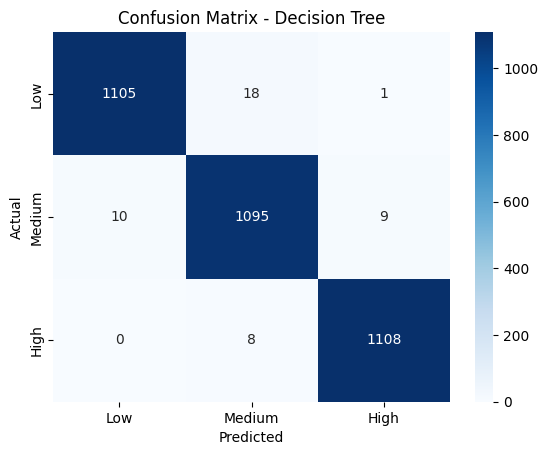

              precision    recall  f1-score   support

        High       0.99      0.99      0.99      1116
         Low       0.99      0.98      0.99      1124
      Medium       0.98      0.98      0.98      1114

    accuracy                           0.99      3354
   macro avg       0.99      0.99      0.99      3354
weighted avg       0.99      0.99      0.99      3354



In [25]:
best_name = classification_table.iloc[0]['Model']
best_model = classification_models[best_name]
best_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test_class, best_pred, labels=['Low', 'Medium', 'High'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'Medium', 'High'],
            yticklabels=['Low', 'Medium', 'High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_name}')
plt.show()

print(classification_report(y_test_class, best_pred, zero_division=0))


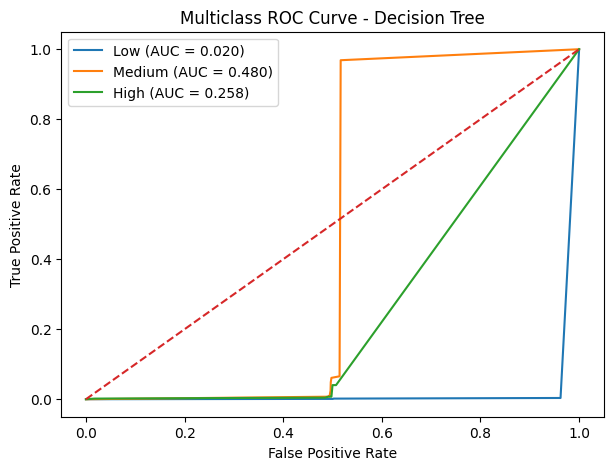

In [26]:
from sklearn.preprocessing import label_binarize

class_order = ['Low', 'Medium', 'High']
y_test_bin = label_binarize(y_test_class, classes=class_order)
proba = best_model.predict_proba(X_test)

plt.figure(figsize=(7, 5))
for i, class_name in enumerate(class_order):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{class_name} (AUC = {class_auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'Multiclass ROC Curve - {best_name}')
plt.legend()
plt.show()


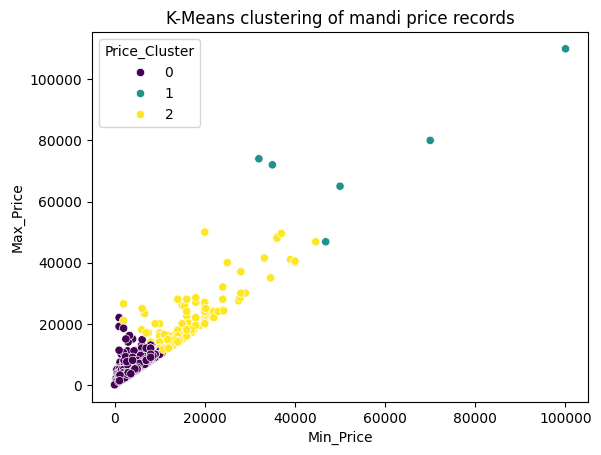

In [27]:
cluster_data = df[['Min_Price', 'Max_Price']].copy()
cluster_scaled = StandardScaler().fit_transform(cluster_data)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Price_Cluster'] = kmeans.fit_predict(cluster_scaled)

sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=42),
                x='Min_Price', y='Max_Price', hue='Price_Cluster',
                palette='viridis')
plt.title('K-Means clustering of mandi price records')
plt.show()
